In [ ]:
%pip install  pandas numpy matplotlib seaborn scipy


Note: you may need to restart the kernel to use updated packages.
Found existing installation: ipywidgets 8.1.9
Uninstalling ipywidgets-8.1.9:
  Would remove:
    /home/shreyansh1812/Desktop/Equilym/env/lib/python3.12/site-packages/ipywidgets-8.1.9.dist-info/*
    /home/shreyansh1812/Desktop/Equilym/env/lib/python3.12/site-packages/ipywidgets/*
Proceed (Y/n)? ERROR: Operation cancelled by user
^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("healthcare_performance.csv")

df["month"] = pd.to_datetime(df["month"], format="%Y-%m")

display(df.head())
print("Dataset shape:", df.shape)

,month,district,anc_coverage,institutional_delivery,immunization,high_risk_cases
0,2026-04-01,Ahmedabad,83,89,91,12
1,2026-04-01,Bhavnagar,75,80,85,19
2,2026-04-01,Mehsana,82,87,90,13
3,2026-04-01,Rajkot,77,83,87,17
4,2026-04-01,Surat,79,85,89,15


Dataset shape: (30, 6)


# Statistical Analysis

In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
display(df.isnull().sum())

required_columns = [
    "month", "district", "anc_coverage",
    "institutional_delivery", "immunization",
    "high_risk_cases"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Required columns validated.")

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   month                   30 non-null     datetime64[us]
 1   district                30 non-null     str           
 2   anc_coverage            30 non-null     int64         
 3   institutional_delivery  30 non-null     int64         
 4   immunization            30 non-null     int64         
 5   high_risk_cases         30 non-null     int64         
dtypes: datetime64[us](1), int64(4), str(1)
memory usage: 1.8 KB

Statistical summary:


,month,anc_coverage,institutional_delivery,immunization,high_risk_cases
count,30,30.000000,30.000000,30.000000,30.000000
mean,2026-05-31 19:12:00,80.133333,87.166667,90.633333,13.466667
min,2026-04-01 00:00:00,42.000000,80.000000,85.000000,6.000000
25%,2026-05-01 00:00:00,78.000000,84.250000,89.000000,11.000000
50%,2026-06-01 00:00:00,80.500000,87.500000,91.000000,13.000000
75%,2026-07-01 00:00:00,84.000000,90.000000,92.000000,15.750000
max,2026-08-01 00:00:00,91.000000,94.000000,97.000000,28.000000
std,NaN,8.732552,3.751628,2.988291,4.336957



Missing values:


month                     0
district                  0
anc_coverage              0
institutional_delivery    0
immunization              0
high_risk_cases           0
dtype: int64

Required columns validated.


# Trend Detection 


In [4]:
TREND_THRESHOLD = 10

indicators = [
    "anc_coverage",
    "institutional_delivery",
    "immunization",
    "high_risk_cases"
]

df = df.sort_values(["district", "month"]).copy()
trend_results = []

for indicator in indicators:
    previous = df.groupby("district")[indicator].shift(1)
    current = df[indicator]

    change_pct = ((current - previous) / previous.replace(0, np.nan)) * 100
    flagged = previous.notna() & (change_pct.abs() >= TREND_THRESHOLD)

    for idx in df.index[flagged]:
        change = change_pct.loc[idx]

        trend_results.append({
            "district": df.loc[idx, "district"],
            "month": df.loc[idx, "month"].strftime("%Y-%m"),
            "indicator": indicator,
            "previous_value": previous.loc[idx],
            "current_value": current.loc[idx],
            "change_pct": round(change, 2),
            "trend": "Increase" if change > 0 else "Decrease"
        })

trends_df = pd.DataFrame(trend_results)
display(trends_df)

trends_df.to_csv("trend_detection_results.csv", index=False)

,district,month,indicator,previous_value,current_value,change_pct,trend
0,Ahmedabad,2026-08,anc_coverage,85.0,69,-18.82,Decrease
1,Mehsana,2026-08,anc_coverage,84.0,42,-50.00,Decrease
2,Ahmedabad,2026-08,high_risk_cases,10.0,13,30.00,Increase
3,Bhavnagar,2026-08,high_risk_cases,17.0,15,-11.76,Decrease
4,Mehsana,2026-08,high_risk_cases,11.0,28,154.55,Increase
5,Vadodara,2026-05,high_risk_cases,9.0,8,-11.11,Decrease
6,Vadodara,2026-07,high_risk_cases,8.0,7,-12.50,Decrease
7,Vadodara,2026-08,high_risk_cases,7.0,6,-14.29,Decrease


# Outlier Deteciton

In [5]:
MULTIPLIER = 1.5
outliers = []

for indicator in indicators:
    values = df[indicator].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - MULTIPLIER * iqr
    upper_bound = q3 + MULTIPLIER * iqr

    mask = (df[indicator] < lower_bound) | (df[indicator] > upper_bound)

    for _, row in df[mask].iterrows():
        outliers.append({
            "district": row["district"],
            "month": row["month"].strftime("%Y-%m"),
            "indicator": indicator,
            "value": row[indicator],
            "lower_bound": round(lower_bound, 2),
            "upper_bound": round(upper_bound, 2),
            "outlier_type": "Low" if row[indicator] < lower_bound else "High"
        })

outliers_df = pd.DataFrame(outliers)
display(outliers_df)

outliers_df.to_csv("outlier_detection_results.csv", index=False)
print("Total outliers:", len(outliers_df))

,district,month,indicator,value,lower_bound,upper_bound,outlier_type
0,Mehsana,2026-08,anc_coverage,42,69.00,93.00,Low
1,Vadodara,2026-08,immunization,97,84.50,96.50,High
2,Mehsana,2026-08,high_risk_cases,28,3.88,22.88,High


Total outliers: 3


# Correlation 

,anc_coverage,institutional_delivery,immunization,high_risk_cases
anc_coverage,1.000,0.407,0.446,-0.905
institutional_delivery,0.407,1.000,0.984,-0.732
immunization,0.446,0.984,1.000,-0.753
high_risk_cases,-0.905,-0.732,-0.753,1.000


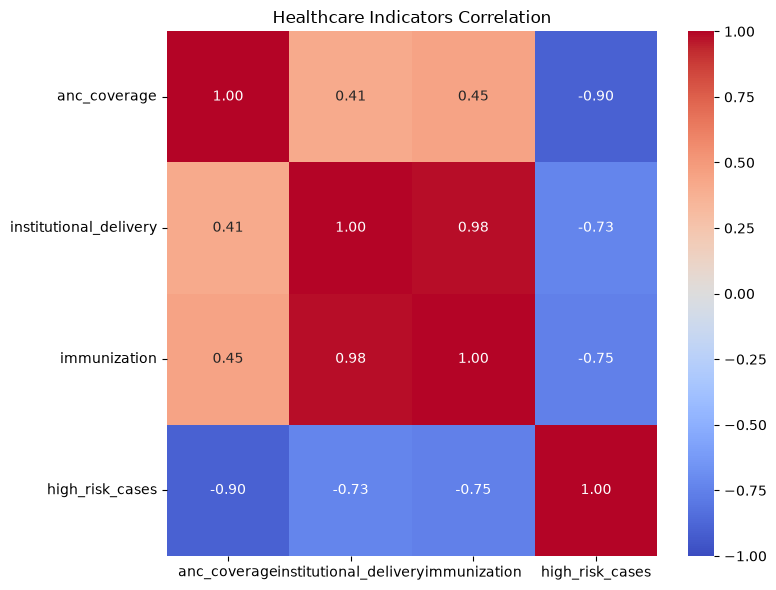

,indicator_1,indicator_2,correlation,relationship
0,anc_coverage,high_risk_cases,-0.905,Negative
1,institutional_delivery,immunization,0.984,Positive
2,institutional_delivery,high_risk_cases,-0.732,Negative
3,immunization,high_risk_cases,-0.753,Negative


In [6]:
CORRELATION_THRESHOLD = 0.70

correlation_matrix = df[indicators].corr(method="pearson")

display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)
plt.title("Healthcare Indicators Correlation")
plt.tight_layout()
plt.show()

correlation_results = []

for i in range(len(indicators)):
    for j in range(i + 1, len(indicators)):
        indicator1 = indicators[i]
        indicator2 = indicators[j]
        correlation = correlation_matrix.loc[indicator1, indicator2]

        if abs(correlation) >= CORRELATION_THRESHOLD:
            correlation_results.append({
                "indicator_1": indicator1,
                "indicator_2": indicator2,
                "correlation": round(correlation, 3),
                "relationship": "Positive" if correlation > 0 else "Negative"
            })

correlation_results_df = pd.DataFrame(correlation_results)
display(correlation_results_df)

correlation_matrix.to_csv("correlation_matrix.csv")
correlation_results_df.to_csv("correlation_results.csv", index=False)

# Insights Generation

In [7]:
insights = []

def add_insight(insight_type, indicator, entity, period,
                metric, change, severity, explanation):
    insights.append({
        "insight_id": f"INS-{len(insights) + 1:04d}",
        "type": insight_type,
        "indicator": indicator,
        "entity": entity,
        "period": period,
        "metric": metric,
        "change": change,
        "severity": severity,
        "explanation": explanation
    })


for _, row in trends_df.iterrows():
    change = row["change_pct"]
    magnitude = abs(change)

    severity = "High" if magnitude >= 30 else "Medium" if magnitude >= 20 else "Low"

    add_insight(
        "trend",
        row["indicator"],
        row["district"],
        row["month"],
        row["current_value"],
        change,
        severity,
        f"{row['indicator']} in {row['district']} "
        f"{row['trend'].lower()}d by {magnitude:.2f}% "
        f"compared with the previous month."
    )


for _, row in outliers_df.iterrows():
    value = row["value"]
    distance = (
        row["lower_bound"] - value
        if value < row["lower_bound"]
        else value - row["upper_bound"]
    )

    severity = "High" if distance >= 10 else "Medium" if distance >= 5 else "Low"

    add_insight(
        "outlier",
        row["indicator"],
        row["district"],
        row["month"],
        value,
        round(distance, 2),
        severity,
        f"{row['indicator']} in {row['district']} was {value:g}, "
        f"outside the IQR bounds of {row['lower_bound']:.2f} "
        f"to {row['upper_bound']:.2f}."
    )


period = (
    f"{df['month'].min():%Y-%m} to {df['month'].max():%Y-%m}"
)

for _, row in correlation_results_df.iterrows():
    correlation = row["correlation"]
    severity = "High" if abs(correlation) >= 0.90 else "Medium"
    pair = f"{row['indicator_1']} / {row['indicator_2']}"

    add_insight(
        "correlation",
        pair,
        "All districts",
        period,
        correlation,
        correlation,
        severity,
        f"{pair} have a {row['relationship'].lower()} Pearson "
        f"correlation of {correlation:.2f}. "
        f"Correlation does not imply causation."
    )


insights_df = pd.DataFrame(insights)
display(insights_df)

insights_df.to_csv("insights.csv", index=False)
print("Total insights generated:", len(insights_df))

,insight_id,type,indicator,entity,period,metric,change,severity,explanation
0,INS-0001,trend,anc_coverage,Ahmedabad,2026-08,69.000,-18.820,Low,anc_coverage in Ahmedabad decreased by 18.82% ...
1,INS-0002,trend,anc_coverage,Mehsana,2026-08,42.000,-50.000,High,anc_coverage in Mehsana decreased by 50.00% co...
2,INS-0003,trend,high_risk_cases,Ahmedabad,2026-08,13.000,30.000,High,high_risk_cases in Ahmedabad increased by 30.0...
3,INS-0004,trend,high_risk_cases,Bhavnagar,2026-08,15.000,-11.760,Low,high_risk_cases in Bhavnagar decreased by 11.7...
4,INS-0005,trend,high_risk_cases,Mehsana,2026-08,28.000,154.550,High,high_risk_cases in Mehsana increased by 154.55...
5,INS-0006,trend,high_risk_cases,Vadodara,2026-05,8.000,-11.110,Low,high_risk_cases in Vadodara decreased by 11.11...
6,INS-0007,trend,high_risk_cases,Vadodara,2026-07,7.000,-12.500,Low,high_risk_cases in Vadodara decreased by 12.50...
7,INS-0008,trend,high_risk_cases,Vadodara,2026-08,6.000,-14.290,Low,high_risk_cases in Vadodara decreased by 14.29...
8,INS-0009,outlier,anc_coverage,Mehsana,2026-08,42.000,27.000,High,"anc_coverage in Mehsana was 42, outside the IQ..."
9,INS-0010,outlier,immunization,Vadodara,2026-08,97.000,0.500,Low,"immunization in Vadodara was 97, outside the I..."


Total insights generated: 15
